# HDSoC event-builder QA
Two-board UDP simulator → frontend collectors → builder → MIDAS → unpacker → ROOT.
Choose `no_cuts` or `dummy_cut` below. Empty/cut collection cycles retain the three bank headers.
The waveform is ADC counts, with one smooth pulse with a fast rise and slower exponential decay across window packets; no hardware calibration is applied.
Source notebooks contain no outputs; executed copies and figures live under `.artifacts`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
APP = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'notebooks/notebook_support.py').exists())
sys.path.insert(0, str(APP/'notebooks'))
from notebook_support import open_data, integer
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True})

In [2]:
DATASET = 'no_cuts'  # Change to 'dummy_cut' to inspect cleared payloads.
DATA_FILE = APP / '.artifacts/hdsoc_builder_qa' / DATASET / 'output.root'
MANIFEST_FILE = Path(DATA_FILE).parent / 'verification.json'
CHECK_SIMULATOR = True  # Set False for hardware recordings.

In [3]:
root_file, tree, resolved = open_data('HDSoC', DATA_FILE)
OUTPUT = Path(resolved).parent / 'figures'
OUTPUT.mkdir(exist_ok=True)
report = json.loads(Path(MANIFEST_FILE).read_text()) if Path(MANIFEST_FILE).is_file() else None
if report:
    print('Independent wire/ROOT verification:', report['status'])
    print('Observed bank payloads (excluding MIDAS framing):')
    display(pd.DataFrame.from_dict(report['banks'], orient='index').rename_axis('bank'))
def save(name):
    plt.gcf().savefig(OUTPUT/(name+'.png'), dpi=150, bbox_inches='tight')
    plt.gcf().savefig(OUTPUT/(name+'.pdf'), bbox_inches='tight')
    plt.show()

HDSoC: /home/jack/cpp_projects/analysis_pipeline_project/apps/midas_file_unpacker_app/.artifacts/hdsoc_builder_qa/no_cuts/output.root
246 entries; ROOT 6.32.02
Independent wire/ROOT verification: PASS
Observed bank payloads (excluding MIDAS framing):


,records,min_bytes,max_bytes
bank,,,
HB00,246,32,156306
HC00,246,80,80
HS00,246,88,88


## Wire layout and decoded products
All numeric envelope/header fields use little endian. Each nested `HD` retains the collector ABI;
its 32 ADC values per packet are big endian. The unpacker preserves these packet words and builds native ADC waveforms.
`HB00` → `NaluBuilderEvent.sources[]` → `{board, event: NaluEvent, has_timing, timing: NaluTimeData}`.
`HC00` → `NaluCollectionTiming`; `HS00` → `NaluSelectionSummary`.
Legacy direct frontend `HD00`/`HT00` remain `NaluEvent`/`NaluTime`. All banks are optional and have `has_nalu_*` flags in ROOT.

In [4]:
schemas = {
'HB00 header (32 B)': [(0,'char[4]','magic = HEB1'),(4,'uint16','version = 1'),(6,'uint16','flags: bit0 final, bit1 timestamp grouping'),(8,'uint64','start_ns (host time since BOR)'),(16,'uint64','end_ns (host time since BOR)'),(24,'uint32','source_events'),(28,'uint32','packets')],
'HB00 source record (12 B + HD + optional HT)': [(0,'uint16','board'),(2,'uint16','reserved = 0'),(4,'uint32','data_bytes'),(8,'uint32','timing_bytes (0 or 64)'),(12,'byte[data_bytes]','HD event'),('12 + data_bytes','byte[timing_bytes]','HT timing')],
'Nested HD header (36 B)': [(0,'uint16','event_header'),(2,'uint8','event_info'),(3,'uint32','event_index'),(7,'uint32','event_reference_time (hardware ticks)'),(11,'uint32','time_threshold (ticks)'),(15,'uint32','event_completion_time_us'),(19,'uint32','clock_frequency (Hz)'),(23,'uint16','packet_size = 80'),(25,'uint64','channel_mask'),(33,'uint8','num_windows'),(34,'uint16','num_packets'),(36,'Packet[num_packets]','packets'),('36 + 80*num_packets','uint16','event_footer')],
'Nested Packet (80 B / 32 ADC samples)': [(0,'uint16','packet_header'),(2,'uint8','packet_info'),(3,'uint8','channel'),(4,'uint32','trigger_time'),(8,'uint16','logical_position'),(10,'uint16','window_position'),(12,'uint16_be[32]','ADC samples'),(76,'uint16','parser_index'),(78,'uint16','packet_footer')],
'Nested HT timing (64 B)': [(0,'uint64','collection_cycle_index'),(8,'uint64','collection_cycle_timestamp_ns'),(16,'double','udp_time (s)'),(24,'double','parse_time (s)'),(32,'double','event_time (s)'),(40,'double','total_time (s)'),(48,'uint64','data_processed (bytes)'),(56,'double','data_rate (MiB/s)')],
'HC00 (80 B)': [(0,'char[4]','magic = HCT1'),(4,'uint16','version = 1'),(6,'uint16','record_size = 80')] + [(8+8*i,'uint64',name) for i,name in enumerate(['cycle_id','start_ns','end_ns','input_events','input_packets','output_events','output_packets','processing_ns','flags (bit0 final)'])],
'HS00 (88 B)': [(0,'char[4]','magic = HSS1'),(4,'uint16','version = 1'),(6,'uint16','record_size = 88'),(8,'uint64','cycle_id'),(16,'char[32]','id (NUL terminated)'),(48,'uint32','enabled'),(52,'int32','priority'),(56,'uint64','evaluated_events'),(64,'uint64','modified_events'),(72,'uint64','evaluated_packets'),(80,'uint64','removed_packets')],
}
for name, rows in schemas.items():
    print(name)
    print(pd.DataFrame(rows, columns=['offset','type','field']).to_string(index=False))
    print()

HB00 header (32 B)
 offset    type                                      field
      0 char[4]                               magic = HEB1
      4  uint16                                version = 1
      6  uint16 flags: bit0 final, bit1 timestamp grouping
      8  uint64             start_ns (host time since BOR)
     16  uint64               end_ns (host time since BOR)
     24  uint32                              source_events
     28  uint32                                    packets

HB00 source record (12 B + HD + optional HT)
         offset               type                  field
              0             uint16                  board
              2             uint16           reserved = 0
              4             uint32             data_bytes
              8             uint32 timing_bytes (0 or 64)
             12   byte[data_bytes]               HD event
12 + data_bytes byte[timing_bytes]              HT timing

Nested HD header (36 B)
             offset             

## Integrity and selection accounting
Check every retained waveform against the simulator model, board/source identities, bank counter agreement,
and monotonic periodic windows. The independent verification report additionally compares all ROOT fields with the MIDAS bytes.
A selection clears data within a collection cycle; it does not remove the cycle's bank set.

In [5]:
cycles, hits, examples = [], [], {}
seen = {0: set(), 1: set()}
verified_samples = 0
for entry in range(tree.GetEntries()):
    tree.GetEntry(entry)
    assert tree.has_nalu_builder_event and tree.has_nalu_collection_timing and tree.has_nalu_selection_summary
    b, c, s = tree.nalu_builder_event, tree.nalu_collection_timing, tree.nalu_selection_summary
    assert int(c.cycle_id) == int(s.cycle_id)
    assert (int(b.start_ns),int(b.end_ns),int(b.source_events),int(b.packets)) == (int(c.start_ns),int(c.end_ns),int(c.output_events),int(c.output_packets))
    assert int(c.input_packets) == int(c.output_packets) + int(s.removed_packets)
    assert len(b.sources) == int(b.source_events)
    packets = 0
    for source in b.sources:
        board = int(source.board)
        ev = source.event
        identity = int(ev.header.event_index)
        assert board in seen and identity not in seen[board]
        seen[board].add(identity)
        packets += len(ev.packets.packets)
        assert len(ev.packets.packets) == int(ev.header.num_packets)
        windows = integer(ev.header.num_windows)
        for wf in ev.waveforms.waveforms:
            channel = int(wf.channel_num)
            trace = np.array(wf.trace, dtype=np.int32, copy=True)
            assert len(trace) == windows*32
            if CHECK_SIMULATOR:
                rise, fall = min(6.0, windows), 6*min(6.0, windows)
                onset = windows*16-min(24,windows*4)+channel%9-4
                t = np.maximum(0,np.arange(len(trace))-onset)
                peak_t = np.log(6)/(1/rise-1/fall)
                norm = np.exp(-peak_t/fall)-np.exp(-peak_t/rise)
                model = 1800+channel+np.floor(480*(np.exp(-t/fall)-np.exp(-t/rise))/norm+0.5).astype(int)
                np.testing.assert_array_equal(trace,model)
            verified_samples += len(trace)
            hits.append((board,channel,len(trace),int(trace.max()),int(trace.min()),int(np.argmax(trace))))
            examples.setdefault((board,channel),trace)
    assert packets == int(b.packets)
    cycles.append((entry,int(c.cycle_id),int(c.start_ns),int(c.end_ns),int(c.input_events),int(c.output_events),int(c.input_packets),int(c.output_packets),int(s.removed_packets),int(s.evaluated_events),int(s.modified_events),int(c.processing_ns),bool(s.enabled),str(s.id),int(s.priority),int(b.flags)))
cycles = pd.DataFrame(cycles,columns=['entry','cycle_id','start_ns','end_ns','input_events','output_events','input_packets','output_packets','removed_packets','evaluated_events','modified_events','processing_ns','cut_enabled','cut_id','priority','flags'])
hits = pd.DataFrame(hits,columns=['board','channel','samples','peak','baseline','peak_sample'])
assert len(cycles) > 0 and not hits.empty
assert np.all(np.diff(cycles.cycle_id) == 1)
periodic = (cycles['flags'].to_numpy() & 2) == 0
if np.all(periodic):
    assert np.array_equal(cycles.start_ns.to_numpy()[1:],cycles.end_ns.to_numpy()[:-1])
if not cycles.cut_enabled.any():
    assert cycles.removed_packets.sum() == 0
    for indices in seen.values(): assert indices == set(range(len(indices)))
if report:
    assert len(cycles) == report['counts']['events']
    assert len(hits) == report['counts']['waveforms']
    assert verified_samples == report['counts']['samples']
    assert cycles.removed_packets.sum() == report['counts']['removed_packets']
print(f'PASS: {len(cycles):,} collection cycles; {len(hits):,} waveforms; {verified_samples:,} ADC samples verified')
print(f'Empty output cycles: {(cycles.output_events==0).sum():,}; removed packets: {cycles.removed_packets.sum():,}')
display(cycles[['cut_id','cut_enabled','priority']].drop_duplicates())
display(hits.groupby('board').agg(waveforms=('channel','size'),samples_per_waveform=('samples','first')))
display(cycles[['input_events','output_events','input_packets','output_packets','removed_packets','evaluated_events','modified_events']].sum().to_frame('total'))

PASS: 246 collection cycles; 2,752 waveforms; 5,371,904 ADC samples verified
Empty output cycles: 160; removed packets: 0


,cut_id,cut_enabled,priority
0,dummy,False,200


,waveforms,samples_per_waveform
board,,
0,1344,1952
1,1408,1952


,total
input_events,86
output_events,86
input_packets,167872
output_packets,167872
removed_packets,0
evaluated_events,0
modified_events,0


## Waveform shape across packet boundaries
Dashed lines mark 32-sample packet boundaries near the pulse. The full waveform has a single pulse,
including at 61 windows / 1,952 samples; ADC values remain in counts.

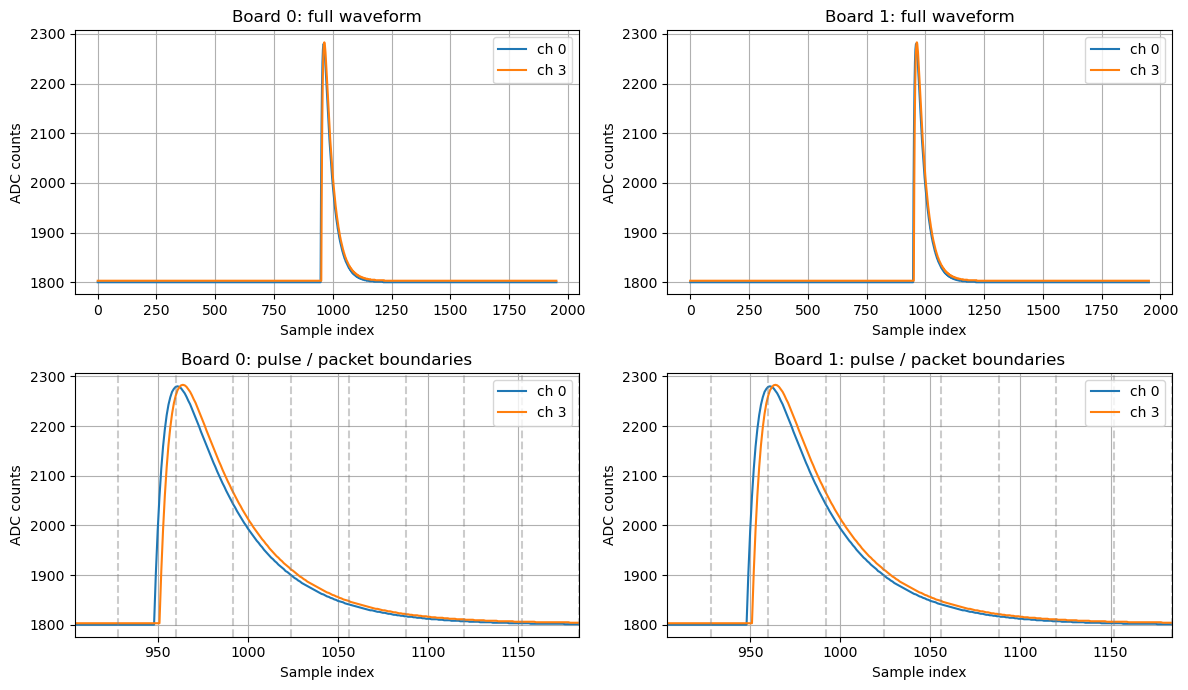

In [6]:
fig, axes = plt.subplots(2,2, figsize=(12,7))
for board in (0,1):
    for channel in (0,3):
        trace = examples[(board,channel)]
        axes[0,board].plot(np.arange(len(trace)),trace,label=f'ch {channel}')
        peak = int(np.argmax(trace))
        axes[1,board].plot(np.arange(len(trace)),trace,label=f'ch {channel}')
    for x in range(max(0,(peak-60)//32)*32,min(len(trace),peak+221),32):
        axes[1,board].axvline(x,color='gray',linestyle='--',alpha=.4)
    axes[0,board].set_title(f'Board {board}: full waveform')
    axes[1,board].set_xlim(max(0,peak-60),min(len(trace),peak+220))
    axes[1,board].set_title(f'Board {board}: pulse / packet boundaries')
    for ax in axes[:,board]: ax.set_xlabel('Sample index');ax.set_ylabel('ADC counts');ax.legend()
plt.tight_layout();save('waveforms')

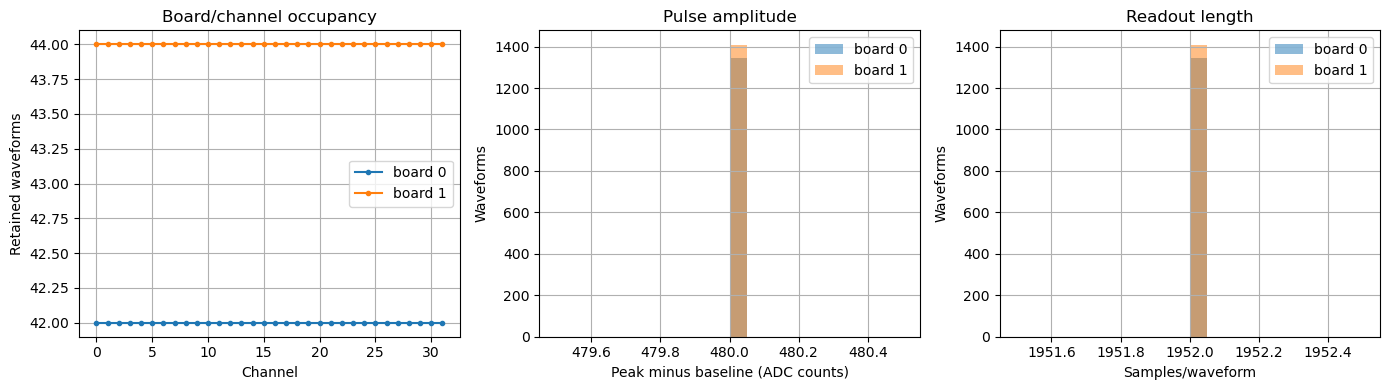

In [7]:
fig, axes = plt.subplots(1,3, figsize=(14,4))
for board, group in hits.groupby('board'):
    occupancy = group.groupby('channel').size()
    axes[0].plot(occupancy.index,occupancy.values,marker='.',label=f'board {board}')
    axes[1].hist(group.peak-group.baseline,bins=20,alpha=.5,label=f'board {board}')
    axes[2].hist(group.samples,bins=20,alpha=.5,label=f'board {board}')
axes[0].set(xlabel='Channel',ylabel='Retained waveforms',title='Board/channel occupancy')
axes[1].set(xlabel='Peak minus baseline (ADC counts)',ylabel='Waveforms',title='Pulse amplitude')
axes[2].set(xlabel='Samples/waveform',ylabel='Waveforms',title='Readout length')
for ax in axes:ax.legend()
plt.tight_layout();save('occupancy_and_signal')

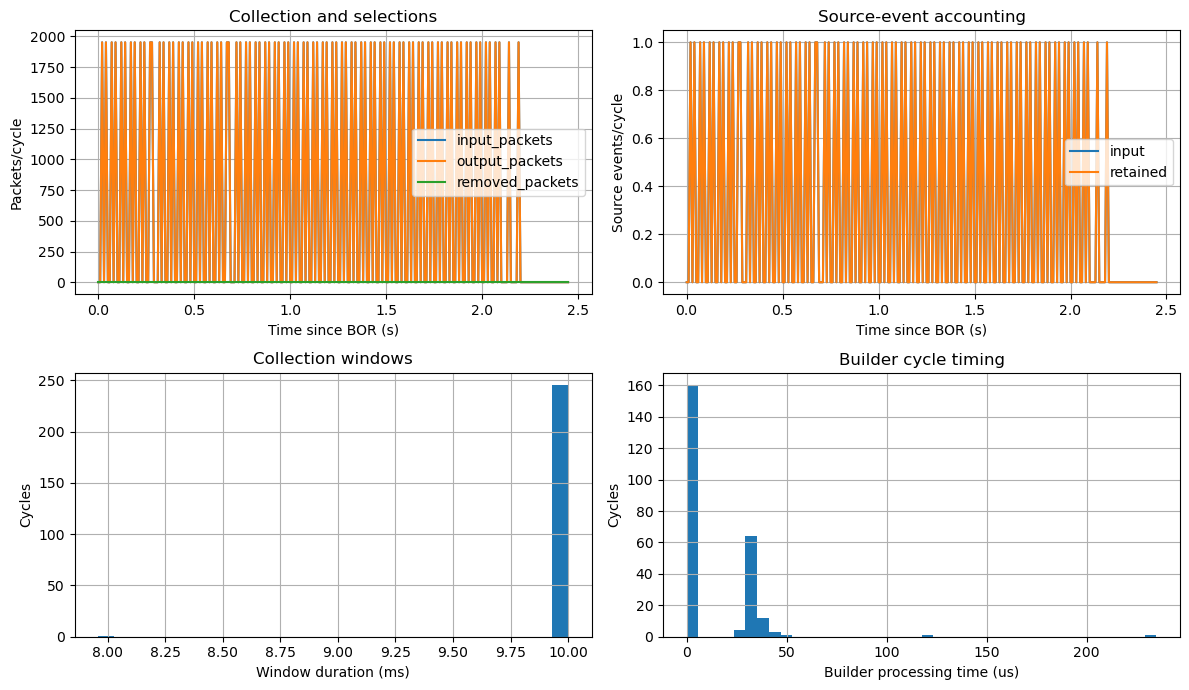

Figures saved to /home/jack/cpp_projects/analysis_pipeline_project/apps/midas_file_unpacker_app/.artifacts/hdsoc_builder_qa/no_cuts/figures


In [8]:
fig, axes = plt.subplots(2,2, figsize=(12,7))
t = cycles.start_ns / 1e9
for column in ['input_packets','output_packets','removed_packets']:
    axes[0,0].plot(t,cycles[column],label=column)
axes[0,0].set(xlabel='Time since BOR (s)',ylabel='Packets/cycle',title='Collection and selections');axes[0,0].legend()
axes[0,1].plot(t,cycles.input_events,label='input')
axes[0,1].plot(t,cycles.output_events,label='retained')
axes[0,1].set(xlabel='Time since BOR (s)',ylabel='Source events/cycle',title='Source-event accounting');axes[0,1].legend()
axes[1,0].hist((cycles.end_ns-cycles.start_ns)/1e6,bins=30)
axes[1,0].set(xlabel='Window duration (ms)',ylabel='Cycles',title='Collection windows')
axes[1,1].hist(cycles.processing_ns/1000,bins=40)
axes[1,1].set(xlabel='Builder processing time (us)',ylabel='Cycles',title='Builder cycle timing')
plt.tight_layout();save('collection_and_cuts')
print('Figures saved to', OUTPUT)
root_file.Close()